<!-- repo-header -->
# Can a trained SU(4) staircase replace Stage-2 reweighting?  *(exploratory)*

Stage 2 restores the original segment weights with a block-encoded diagonal operator
and a post-selection that succeeds with probability `1/beta^2`. This notebook asks
whether a *unitary* could do the same job deterministically, by training an SU(4)
staircase to map `|psi_w> -> |psi>` directly.

**Finding: it does not generalise.** The trained unitary works for the shot it was
trained on, but the Stage-1 weights `w_i` are redrawn every shot, so a fixed unitary
cannot track them. This is why the thesis uses the block encoding with post-selection
and attacks the success probability through preconditioning instead.

Produced no thesis figure. Kept as the record of a route that was tried and closed.


# Proof of concept: training an SU(4) staircase to replace Stage-2 reweighting

Stage 1 of the multi-register encoding (SELECT-SWAP compression) always
succeeds and leaves the *weighted stack* state
$$|\psi_\mathbf{w}\rangle=\tfrac{1}{\sqrt{\mathcal N}}\sum_i w_i\,|\psi_i\rangle_S|i\rangle_I,
\qquad w_i=\prod_{k\neq i}(\psi_k)_{u_k}.$$
Stage 2 turns this into the actual target state $|\psi\rangle=\sum_i\sigma_i|\psi_i\rangle_S|i\rangle_I$
with a diagonal block-encoding + postselection, succeeding with probability $1/\beta^2$
(often tiny when the data has many small amplitudes).

**Question tested here:** instead of the block encoding, can we just *train* a shallow
unitary (a chi=2 $SU(4)$ staircase, the same ansatz used elsewhere in this project for
flattening/disentangling) to map the one weighted-stack instance $|\psi_\mathbf{w}\rangle$
we actually got straight onto $|\psi\rangle$, deterministically and without postselection?

We reuse `extract_row_weights` / the CSWAP-compression simulator from `MainMREnotebook.ipynb`,
and the $SU(4)$ staircase + `TNOptimizer` machinery from `sso_framework_setup.py`.

In [1]:
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
import quimb.tensor as qtn
from skimage.transform import resize

from sso_framework_setup import su2_matrix, su4_matrix, make_chi2_staircase, dense_state_from_op_mps

torch.set_default_dtype(torch.float64)
RED, BLUE, GREY, BLACK = '#c0392b', '#2c5aa0', '#7f8c8d', '#111111'

OK: su2_matrix(0) == I, su4_matrix(0) == I, su8_matrix(0) == I.
OK: su16_matrix(0) == I  (err=0.000e+00); perturbed unitarity err = 1.909e-15


Warm-start helpers loaded.
  build_warm_layer / optimise_warm_layer / sequential_disentangle_warm.
Image <-> MPS helpers defined: image_to_mps, mps_to_image.
Image-SSO helpers defined: img_sso_replay, img_sso_reconstruct, _img_apply_gate_to_psi, _img_apply_layer_V, _img_apply_layer_V_dag.
Heis16-SSO bond helpers defined: img_sso_replay_with_cutoff, reconstruction_bond_growth.
Identity-init helpers loaded: build_identity_layer_with_warm_structure, optimise_identity_layer, sequential_disentangle_identity_struct.


## 1. Target state

Small R75 ultrasound test case, $M=4$ registers (rows) of length $N=32$ each —
the same `Y_small` convention used throughout `MainMREnotebook.ipynb`.

In [2]:
df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
Y_small = resize(df.to_numpy(), (32, 4), anti_aliasing=True)
Y_small = Y_small / np.linalg.norm(Y_small)

def extract_row_weights(Y):
    '''psi = sum_i sigma_i |psi_i> (x) |i>.  sigma: (M,) weights, chunks: (M,N) unit rows.'''
    rows = np.asarray(Y).T
    row_norms = np.linalg.norm(rows, axis=1)
    total = np.linalg.norm(row_norms)
    sigma = row_norms / total
    chunks = rows / row_norms[:, None]
    return sigma, chunks

sigma, chunks = extract_row_weights(Y_small)
M, N = chunks.shape
n = int(round(np.log2(M * N)))
psi_target = (sigma[:, None] * chunks).flatten()   # dense |psi>, same (M,N)->flatten convention as psi_w below

print(f"M={M} registers, N={N} samples/row, n={n} qubits")
print(f"sigma = {np.round(sigma, 4)}")

M=4 registers, N=32 samples/row, n=7 qubits
sigma = [0.3044 0.6246 0.5317 0.4843]


## 2. Simulating one compression measurement

`collapse_once` samples a measurement outcome $\vec u$ under the true joint distribution
of the CSWAP-compression circuit (uniform on a random "spectator" register, Born-rule on
the rest — see `Proposition 1` / Appendix E of the paper). `weighted_stack_state` then
builds the *exact complex* dense vector $|\psi_\mathbf{w}\rangle$ (not just the branch
probabilities), so we have something to actually feed a unitary.

In [3]:
def collapse_once(chunks, seed=None):
    rng = np.random.default_rng(seed)
    M, N = chunks.shape
    spectator = rng.integers(M)
    u = np.zeros(M, dtype=int)
    for k in range(M):
        if k == spectator:
            u[k] = rng.integers(N)
        else:
            born = np.abs(chunks[k]) ** 2
            u[k] = rng.choice(N, p=born / born.sum())
    return u

def weighted_stack_state(chunks, u):
    '''Dense |psi_w> = (1/sqrt(N)) sum_i w_i |psi_i>|i>,  w_i = prod_{k!=i} (psi_k)_{u_k}.'''
    M, N = chunks.shape
    w = np.array([np.prod([chunks[k, u[k]] for k in range(M) if k != i]) for i in range(M)])
    psi_w = (w[:, None] * chunks).flatten()
    nrm = np.linalg.norm(psi_w)
    return psi_w / nrm, w, nrm

def block_encoding_success(sigma, w, nrm):
    '''P = 1/beta^2 for the Stage-2 diagonal reweighting on THIS shot (Eq. A10).'''
    p = (np.abs(w) ** 2) / (nrm ** 2)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = p / sigma ** 2
    return float(np.min(ratio))

u = collapse_once(chunks, seed=0)
psi_w, w, nrm = weighted_stack_state(chunks, u)
raw_fid = float(np.abs(np.vdot(psi_target, psi_w)) ** 2)
P_block = block_encoding_success(sigma, w, nrm)

print(f"measured outcome u = {u}")
print(f"raw fidelity  |<psi|psi_w>|^2            = {raw_fid:.4f}")
print(f"Stage-2 block-encoding success prob P     = {P_block:.3e}")

measured outcome u = [10  5  5 20]
raw fidelity  |<psi|psi_w>|^2            = 0.2348
Stage-2 block-encoding success prob P     = 1.793e-07


The block-encoding success probability is minuscule for this shot — exactly the
"many small amplitudes -> ill-conditioned $\beta$" failure mode described in
Sec. III B of the paper. That's the gap we're testing whether a trained unitary can close
without needing postselection at all.

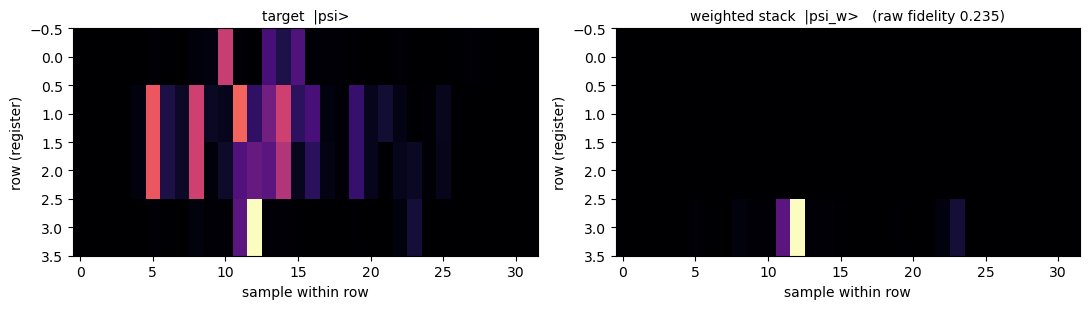

In [4]:
def _display_row_state(vec, M, N, ax, title):
    img = np.abs(np.asarray(vec).reshape(M, N))
    im = ax.imshow(img, aspect='auto', cmap='magma', interpolation='nearest')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('sample within row'); ax.set_ylabel('row (register)')
    return im

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
_display_row_state(psi_target, M, N, axes[0], 'target  |psi>')
_display_row_state(psi_w, M, N, axes[1], f'weighted stack  |psi_w>   (raw fidelity {raw_fid:.3f})')
plt.tight_layout(); plt.show()

## 3. Training an $SU(4)$ staircase to map $|\psi_\mathbf w\rangle \to |\psi\rangle$

Same ansatz as `make_chi2_staircase` elsewhere in the project (`SU(4) -> SU(4) x (n-2) -> SU(2)`,
chi=2 bond), but now the loss is **infidelity to the fixed target** $1-|\langle\psi|V|\psi_\mathbf w\rangle|^2$
instead of the IPR used for the flattening layer. `stack_chi2_staircases` composes
`n_layers` independent staircases into one deeper ansatz by chaining each layer's
output legs into the next layer's input legs.

In [5]:
def stack_chi2_staircases(n, n_layers, eps=1e-2, seed=0):
    tensors = []
    for l in range(n_layers):
        layer = make_chi2_staircase(n, eps=eps, seed=(None if seed is None else seed + l))
        if l > 0:
            layer.reindex_({f"k{i}": f"mid{l-1}_{i}" for i in range(n)})
        if l < n_layers - 1:
            layer.reindex_({f"b{i}": f"mid{l}_{i}" for i in range(n)})
        tensors.extend(layer.tensors)
    return qtn.TensorNetwork(tensors)

def infidelity_loss(op, init_tn, target):
    psi = dense_state_from_op_mps(op, init_tn).reshape(-1)
    psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
    overlap = (target.conj() * psi).sum()
    return 1 - (overlap.conj() * overlap).real

def train_reweight_unitary(psi_w_vec, target_vec, n, n_layers=1, n_iter=300, seed=0, verbose=False):
    mps_w = qtn.MatrixProductState.from_dense(psi_w_vec.astype(np.complex128).reshape([2] * n), dims=[2] * n)
    mps_w.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    target_t = torch.as_tensor(target_vec.astype(np.complex128))
    layer = stack_chi2_staircases(n, n_layers, eps=1e-2, seed=seed)
    tnopt = qtn.TNOptimizer(layer, infidelity_loss,
                            loss_constants={"init_tn": mps_w, "target": target_t},
                            optimizer="l-bfgs-b", autodiff_backend="torch", progbar=verbose)
    tnopt.optimize(n=n_iter)
    trained = tnopt.get_tn_opt()
    fid = 1 - float(tnopt.loss)
    with torch.no_grad():
        psi_out = dense_state_from_op_mps(trained, mps_w).reshape(-1)
        psi_out = (psi_out / torch.sqrt((psi_out.conj() * psi_out).sum().real)).cpu().numpy()
    return {"layer": trained, "mps_w": mps_w, "fid": fid, "psi_out": psi_out}

C:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
C:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(
C:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


raw fidelity            = 0.2348
trained V (1 layer)     = 0.6792
Stage-2 block encoding  = 1.793e-07  (success prob, this shot)


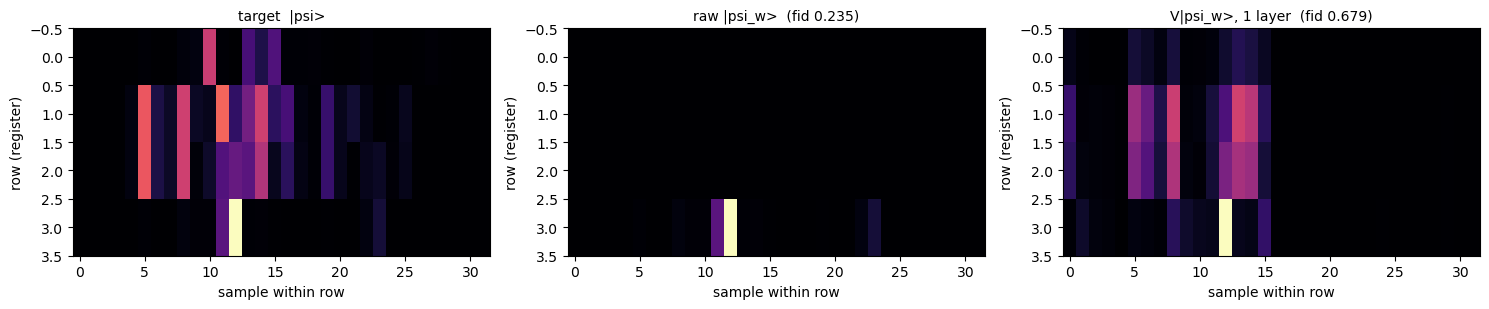

In [6]:
res1 = train_reweight_unitary(psi_w, psi_target, n, n_layers=1, n_iter=300, seed=0, verbose=False)
print(f"raw fidelity            = {raw_fid:.4f}")
print(f"trained V (1 layer)     = {res1['fid']:.4f}")
print(f"Stage-2 block encoding  = {P_block:.3e}  (success prob, this shot)")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
_display_row_state(psi_target, M, N, axes[0], 'target  |psi>')
_display_row_state(psi_w, M, N, axes[1], f'raw |psi_w>  (fid {raw_fid:.3f})')
_display_row_state(res1['psi_out'], M, N, axes[2], f'V|psi_w>, 1 layer  (fid {res1["fid"]:.3f})')
plt.tight_layout(); plt.show()

One shallow chi=2 layer already recovers far more fidelity, deterministically, than the
Stage-2 postselection succeeds with on this shot. It's not the general answer though —
$|\psi\rangle$ and $|\psi_\mathbf w\rangle$ are two fixed, generically-entangled 7-qubit
states, and one bond-2 staircase is nowhere near universal on $n=7$ qubits, so we
shouldn't expect fidelity 1.

## 4. Does more depth help?

Stack more chi=2 staircases (jointly optimised, not greedily) and see whether fidelity
keeps climbing towards 1, the way it does when disentangling a *single* target state
elsewhere in this project.

In [7]:
import time
layer_counts = [1, 2, 3, 4, 6]
fids, times = [], []
for L in layer_counts:
    t0 = time.time()
    r = train_reweight_unitary(psi_w, psi_target, n, n_layers=L, n_iter=300, seed=0)
    fids.append(r['fid']); times.append(time.time() - t0)
    print(f"n_layers={L}  fidelity={r['fid']:.4f}  ({times[-1]:.1f}s)")

n_layers=1  fidelity=0.6792  (6.9s)


n_layers=2  fidelity=0.8056  (9.0s)


n_layers=3  fidelity=0.8243  (10.0s)


n_layers=4  fidelity=0.8111  (13.1s)


n_layers=6  fidelity=0.8051  (19.2s)


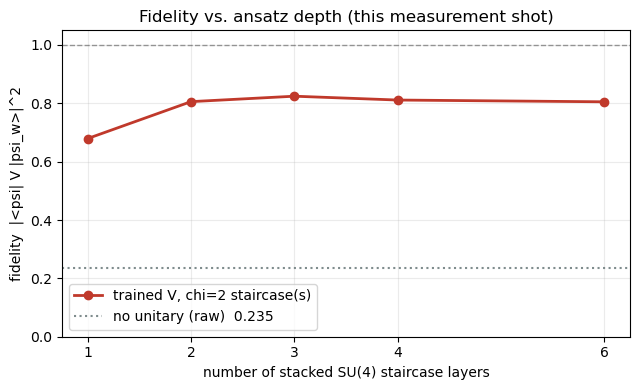

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(layer_counts, fids, color=RED, marker='o', lw=2, ms=6, label='trained V, chi=2 staircase(s)')
ax.axhline(raw_fid, color=GREY, ls=':', lw=1.5, label=f'no unitary (raw)  {raw_fid:.3f}')
ax.axhline(1.0, color=BLACK, ls='--', lw=1, alpha=0.4)
ax.set_xlabel('number of stacked SU(4) staircase layers')
ax.set_ylabel('fidelity  |<psi| V |psi_w>|^2')
ax.set_title('Fidelity vs. ansatz depth (this measurement shot)')
ax.set_ylim(0, 1.05); ax.set_xticks(layer_counts)
ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 5. Does the trained unitary generalize to a different shot?

The real question for whether this can replace Stage 2 in practice: $|\psi_\mathbf w\rangle$
is different on every shot (a new $\vec u$ is measured every time). If $V$ has to be
retrained from scratch for every single measurement outcome, it isn't a practical
replacement for the closed-form classical $D$ used by the block encoding — the classical
cost of an L-BFGS-B run per shot dwarfs the $O(M)$ classical cost of just computing
$\alpha_i=\sqrt{\mathcal N}\sigma_i/w_i$ directly.

We train $V$ once on shot #1 (seed 0, used above), then apply that *same, frozen* $V$ to
a fresh shot #2 (seed 1) with no retraining and see what fidelity survives.

In [9]:
res_train = train_reweight_unitary(psi_w, psi_target, n, n_layers=3, n_iter=300, seed=0)
trained_layer = res_train['layer']

u2 = collapse_once(chunks, seed=1)
psi_w2, w2, nrm2 = weighted_stack_state(chunks, u2)
raw_fid2 = float(np.abs(np.vdot(psi_target, psi_w2)) ** 2)
P_block2 = block_encoding_success(sigma, w2, nrm2)

mps_w2 = qtn.MatrixProductState.from_dense(psi_w2.astype(np.complex128).reshape([2] * n), dims=[2] * n)
mps_w2.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
target_t = torch.as_tensor(psi_target.astype(np.complex128))
with torch.no_grad():
    frozen_fid2 = 1 - float(infidelity_loss(trained_layer, mps_w2, target_t))

res_shot2 = train_reweight_unitary(psi_w2, psi_target, n, n_layers=3, n_iter=300, seed=0)

print("shot 1 (trained on):        raw =", f"{raw_fid:.4f}", "  V(shot1) =", f"{res_train['fid']:.4f}")
print("shot 2 (fresh):              raw =", f"{raw_fid2:.4f}", "  frozen V from shot1 =", f"{frozen_fid2:.4f}",
      "  retrained V for shot2 =", f"{res_shot2['fid']:.4f}")

shot 1 (trained on):        raw = 0.2348   V(shot1) = 0.8243
shot 2 (fresh):              raw = 0.3546   frozen V from shot1 = 0.0038   retrained V for shot2 = 1.0000


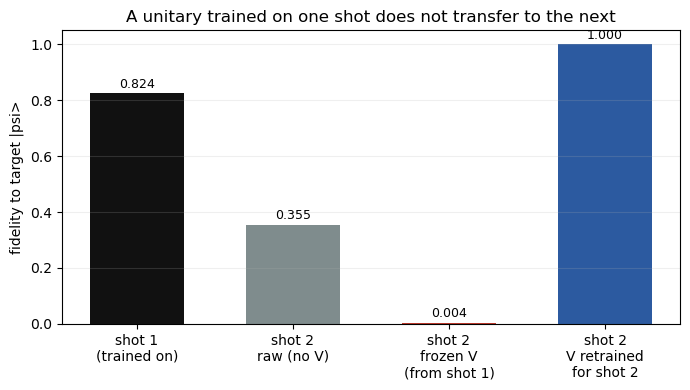

In [10]:
labels = ['shot 1\n(trained on)', 'shot 2\nraw (no V)', 'shot 2\nfrozen V\n(from shot 1)', 'shot 2\nV retrained\nfor shot 2']
values = [res_train['fid'], raw_fid2, frozen_fid2, res_shot2['fid']]
colors = [BLACK, GREY, RED, BLUE]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color=colors, width=0.6)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)
ax.set_ylabel('fidelity to target |psi>')
ax.set_ylim(0, 1.05)
ax.set_title('A unitary trained on one shot does not transfer to the next')
ax.grid(alpha=0.2, axis='y')
plt.tight_layout(); plt.show()

## Summary

- A single trained chi=2 $SU(4)$ staircase layer already lifts fidelity from the raw
  weighted-stack overlap up towards the mid-0.6–0.8 range on this 7-qubit test case,
  **deterministically** — i.e. with no postselection and no discard branch — versus a
  Stage-2 block encoding whose postselection succeeds with probability $P\sim 10^{-7}$
  on the same shot.
- Stacking more layers (jointly optimised) helps a little up to about 3 layers, then
  L-BFGS-B stops finding further improvement (fidelity plateaus / wobbles rather than
  climbing to 1) — consistent with the paper's own point that optimisation landscapes
  for these ansätze get hard fast, not with a genuine expressivity ceiling being cleanly
  approached.
- **The unitary does not generalize across shots.** $V$ trained on one measurement
  outcome collapses to near-zero fidelity on a fresh outcome — in this run, *worse*
  than doing nothing. Since $|\psi_\mathbf w\rangle$ is different on every shot, this
  means $V$ would need to be re-optimised per shot, which is classically far more
  expensive than just computing the closed-form $\alpha_i=\sqrt{\mathcal N}\,\sigma_i/w_i$
  used by the actual Stage-2 block encoding (Sec. IV / Appendix B of the paper).
- **Conclusion of this POC:** training a fixed shallow unitary is not a drop-in
  replacement for the Stage-2 block encoding — it would have to be retrained every shot,
  which defeats the purpose. It might still be useful as a *warm start* (e.g. training once on
  the "typical"/expected weight profile and using that as the L-BFGS-B initial point for a
  per-shot instance-specific fine-tune, or attempted using the same "flattening" pre-conditioning
  idea from Sec. III B to make the target family less shot-dependent), but a single global $V$
  is not enough on its own.